In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap, LogNorm
from matplotlib.patches import Rectangle
from pathlib import Path
from functools import partial
from jcamp import readfile
from kafe2 import XYFit
import statsmodels.api as sm
import locale
import pickle
import yaml

In [2]:
from setup import (
    white,
    gray,
    black,
    colors,
    plot_style,
    filepath,
    testing_labels,
    calibration_labels,
    spectral_range,
    absorption_path_length,
    testing_settling_time,
    calibration_settling_time,
    calibration_type,
    pid_response_factors,
    configuration,
)
from processing import (
    is_system_settled,
    center_spectra,
    broaden_spectrum,
    concentration_from_flowrate,
    voltage_from_concentration,
    concentration_from_voltage,
    scaling_from_pid_to_cell,
    scaling_from_cell_to_pid,
    cm2inch,
    format_number,
)

In [3]:
locale.setlocale(locale.LC_ALL, "en_US.UTF-8")

plt.style.use(plot_style)
plt.rcParams.update(
    {
        "font.size": 8,
        "axes.titlesize": 10,
        "axes.labelsize": 9,
        "xtick.labelsize": 8,
        "ytick.labelsize": 8,
        "legend.fontsize": 8,
        "lines.linewidth": 0.7,
        "patch.linewidth": 0.7,
        "lines.markeredgewidth": 0.7,
        "lines.markersize": 3.5,
        "axes.formatter.use_locale": True,
    }
)

### Load calibration datasets

In [4]:
for labels, settling_time in [
    (calibration_labels, calibration_settling_time),
    (testing_labels, testing_settling_time),
]:
    times = []
    voltages = []
    absorbances = []
    flowrates = []
    setpoints = []
    concentrations_pid_readout = []
    are_settled = []
    are_analyte_free = []
    are_mixtures = []

    wavenumber = None
    spectral_resolution = None
    gas_1 = None
    gas_2 = None
    split_ratio = None
    window_type = None
    correction_type = None
    signal_type = None

    for label in labels:
        dataset = np.load(filepath / f"{label}.npz")
        metadata = yaml.safe_load((filepath / f"{label}.yaml").read_text())

        if spectral_resolution is None:
            spectral_resolution = metadata["sampling"]["spectral_resolution"]
        elif spectral_resolution != metadata["sampling"]["spectral_resolution"]:
            raise ValueError(f"Spectral resolution mismatch for {label}.")

        time = dataset["time"]
        spectrum = dataset["spectrum"]

        if wavenumber is None:
            wavenumber = dataset["wavenumber"]
            spectral_mask = (wavenumber >= spectral_range[0]) & (
                wavenumber <= spectral_range[1]
            )
        elif wavenumber.shape != dataset["wavenumber"].shape:
            raise ValueError(f"Wavenumber mismatch for {label}.")
        elif not np.allclose(wavenumber, dataset["wavenumber"], atol=1e-3):
            raise ValueError(f"Wavenumber mismatch for {label}.")

        if gas_1 is None:
            gas_1 = str(dataset["gas_1"])
        elif gas_1 != str(dataset["gas_1"]):
            raise ValueError(f"Gas 1 mismatch for {label}.")

        if gas_2 is None:
            gas_2 = str(dataset["gas_2"])
        elif gas_2 != str(dataset["gas_2"]):
            raise ValueError(f"Gas 2 mismatch for {label}.")

        if split_ratio is None:
            split_ratio = float(dataset["split_ratio"])
        elif split_ratio != float(dataset["split_ratio"]):
            raise ValueError(f"Split ratio mismatch for {label}.")

        if dataset["type"] == "twins":
            if window_type is None:
                window_type = str(dataset["window_type"])
            elif window_type != str(dataset["window_type"]):
                raise ValueError(f"Window type mismatch for {label}.")

            if correction_type is None:
                correction_type = str(dataset["correction_type"])
            elif correction_type != str(dataset["correction_type"]):
                raise ValueError(f"Correction type mismatch for {label}.")

            if signal_type is None:
                signal_type = str(dataset["signal_type"])
            elif signal_type != str(dataset["signal_type"]):
                raise ValueError(f"Signal type mismatch for {label}.")

        setpoint_0 = dataset["setpoint_0"]
        setpoint_1 = dataset["setpoint_1"]
        setpoint_2 = dataset["setpoint_2"]
        setpoint = np.stack(
            [
                np.mean(setpoint_0, axis=1),
                np.mean(setpoint_1, axis=1),
                np.mean(setpoint_2, axis=1),
            ],
            axis=1,
        )

        is_mixture = np.all(np.round(setpoint[:, 1:], 3) > 0, axis=1)
        if labels is calibration_labels and np.any(is_mixture):
            raise ValueError(f"Setpoints can't be both non-zero for {label}.")

        flowrate_0 = dataset["flowrate_0"]
        flowrate_1 = dataset["flowrate_1"]
        flowrate_2 = dataset["flowrate_2"]
        flowrate = np.stack(
            [
                np.mean(flowrate_0, axis=1),
                np.mean(flowrate_1, axis=1),
                np.mean(flowrate_2, axis=1),
            ],
            axis=1,
        )

        voltage_pid_1 = dataset["voltage_pid_1"] / 1e6  # (V)
        voltage_pid_2 = dataset["voltage_pid_2"] / 1e6  # (V)
        voltage = np.stack(
            [np.mean(voltage_pid_1, axis=1), np.mean(voltage_pid_2, axis=1)],
            axis=1,
        )

        concentration_gas_1 = dataset["concentration_gas_1"]
        concentration_gas_2 = dataset["concentration_gas_2"]
        concentration_pid_readout = np.stack(
            [
                np.mean(concentration_gas_1, axis=1),
                np.mean(concentration_gas_2, axis=1),
            ],
            axis=1,
        )

        time_offset = np.max(np.concatenate(times)) if times else 0
        time = np.min(time, axis=1) + time_offset

        spectrum = spectrum[:, spectral_mask]

        is_settled = is_system_settled(time, setpoint_1, setpoint_2, settling_time)
        is_analyte_free = (
            np.all((setpoint_0 != 0) & (setpoint_1 == 0) & (setpoint_2 == 0), axis=1)
            & is_settled
        )

        if not np.any(is_analyte_free):
            raise ValueError(f"No analyte-free spectra found for {label}.")

        absorbance = -np.log10(spectrum / np.mean(spectrum[is_analyte_free, :], axis=0))

        times.append(time)
        voltages.append(voltage)
        absorbances.append(absorbance)
        flowrates.append(flowrate)
        setpoints.append(setpoint)
        concentrations_pid_readout.append(concentration_pid_readout)
        are_settled.append(is_settled)
        are_analyte_free.append(is_analyte_free)
        are_mixtures.append(is_mixture)

    if labels is calibration_labels:
        times_calibration = np.concatenate(times, axis=0)
        voltages_calibration = np.concatenate(voltages, axis=0)
        absorbances_calibration = np.concatenate(absorbances, axis=0)
        flowrates_calibration = np.concatenate(flowrates, axis=0)
        setpoints_calibration = np.concatenate(setpoints, axis=0)
        concentrations_pid_readout_calibration = np.concatenate(
            concentrations_pid_readout, axis=0
        )
        are_settled_calibration = np.concatenate(are_settled, axis=0)
        are_analyte_free_calibration = np.concatenate(are_analyte_free, axis=0)
        are_mixtures_calibration = np.concatenate(are_mixtures, axis=0)

        gases_calibration = (gas_1, gas_2)
        wavenumber_calibration = wavenumber[spectral_mask]
        spectral_resolution_calibration = spectral_resolution
        split_ratio_calibration = split_ratio
        window_type_calibration = window_type
        correction_type_calibration = correction_type
        signal_type_calibration = signal_type
    if labels is testing_labels:
        times_testing = np.concatenate(times, axis=0)
        voltages_testing = np.concatenate(voltages, axis=0)
        absorbances_testing = np.concatenate(absorbances, axis=0)
        flowrates_testing = np.concatenate(flowrates, axis=0)
        setpoints_testing = np.concatenate(setpoints, axis=0)
        concentrations_pid_readout_testing = np.concatenate(
            concentrations_pid_readout, axis=0
        )
        are_settled_testing = np.concatenate(are_settled, axis=0)
        are_analyte_free_testing = np.concatenate(are_analyte_free, axis=0)
        are_mixtures_testing = np.concatenate(are_mixtures, axis=0)

        gases_testing = (gas_1, gas_2)
        wavenumber_testing = wavenumber[spectral_mask]
        spectral_resolution_testing = spectral_resolution
        split_ratio_testing = split_ratio
        window_type_testing = window_type
        correction_type_testing = correction_type
        signal_type_testing = signal_type

assert gases_calibration == gases_testing, (
    "Gases of calibration and testing dataset don't match"
)
gases = gases_calibration

In [5]:
number_spectra_calibration, number_wavenumbers_calibration = np.shape(
    absorbances_calibration
)
number_gases = len(gases)
gas_labels = {"isopropanol": "iPrOH", "ethanol": "EtOH"}

print(f"Datasets: {', '.join(calibration_labels)}")
print(f"Gases: {', '.join(gas_labels[gas] for gas in gases)}")
print(
    f"Spectra: {number_spectra_calibration} "
    f"({np.sum(are_settled_calibration)} are settled, "
    f"{np.sum(are_analyte_free_calibration)} are analyte free)"
)
print(
    f"Wavenumbers: {number_wavenumbers_calibration} "
    f"at {spectral_resolution_calibration} cm^-1 resolution"
)

Datasets: GRASP26_62F
Gases: iPrOH, EtOH
Spectra: 209 (109 are settled, 59 are analyte free)
Wavenumbers: 30 at 20 cm^-1 resolution


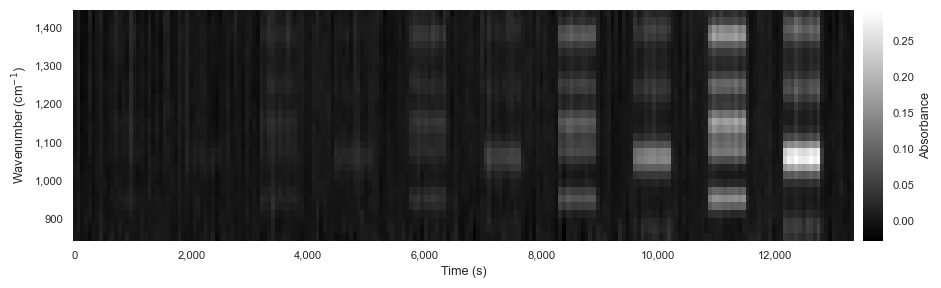

In [6]:
fig, ax = plt.subplots(figsize=(12, 3))

mesh = ax.pcolormesh(
    times_calibration,
    wavenumber_calibration,
    absorbances_calibration.T,
    cmap="gray",
)

ax.set_xlabel("Time (s)")
ax.set_ylabel("Wavenumber (cm$^{-1}$)")

fig.colorbar(mesh, ax=ax, label="Absorbance", aspect=12, pad=0.01)

### Estimate concentrations from NIST spectra

In [7]:
wavenumber_nist = {}
absorption_coefficients_nist_calibration = {}
absorption_coefficients_nist_testing = {}
for gas in gases:
    data_nist = readfile(Path("NIST", f"{gas}.jdx"))

    if data_nist["yunits"] == "TRANSMITTANCE":
        data_nist["y"] = -np.log10(data_nist["y"])

    wavenumber_nist[gas] = data_nist["x"]
    absorption_coefficients_nist_calibration[gas] = broaden_spectrum(
        data_nist["x"],
        data_nist["y"],
        spectral_range,
        spectral_resolution_calibration,
        window_type_calibration,
    )
    absorption_coefficients_nist_testing[gas] = broaden_spectrum(
        data_nist["x"],
        data_nist["y"],
        spectral_range,
        spectral_resolution_testing,
        window_type_testing,
    )

    spectral_mask_nist = (wavenumber_nist[gas] >= spectral_range[0]) & (
        wavenumber_nist[gas] <= spectral_range[1]
    )
    wavenumber_nist[gas] = wavenumber_nist[gas][spectral_mask_nist]
    absorption_coefficients_nist_calibration[gas] = (
        absorption_coefficients_nist_calibration[gas][spectral_mask_nist]
    )
    absorption_coefficients_nist_testing[gas] = absorption_coefficients_nist_testing[
        gas
    ][spectral_mask_nist]

In [8]:
absorption_coefficients_calibration = []
absorption_coefficients_testing = []
for gas in gases:
    absorption_coefficients_calibration.append(
        np.interp(
            wavenumber_calibration,
            wavenumber_nist[gas],
            absorption_coefficients_nist_calibration[gas],
        )
    )
    absorption_coefficients_testing.append(
        np.interp(
            wavenumber_testing,
            wavenumber_nist[gas],
            absorption_coefficients_nist_testing[gas],
        )
    )

absorption_coefficients_calibration = np.stack(
    absorption_coefficients_calibration, axis=1
)
absorption_coefficients_testing = np.stack(absorption_coefficients_testing, axis=1)

absorbances_centered_calibration = center_spectra(absorbances_calibration)
absorption_coefficients_centered_calibration = center_spectra(
    absorption_coefficients_calibration.T
).T
absorbances_centered_testing = center_spectra(absorbances_testing)
absorption_coefficients_centered_testing = center_spectra(
    absorption_coefficients_testing.T
).T

concentration_estimates_nist_calibration, *_ = np.linalg.lstsq(
    absorption_coefficients_centered_calibration * absorption_path_length,
    absorbances_centered_calibration.T,
    rcond=None,
)
concentration_estimates_nist_testing, *_ = np.linalg.lstsq(
    absorption_coefficients_centered_testing * absorption_path_length,
    absorbances_centered_testing.T,
    rcond=None,
)

concentration_estimates_nist_calibration = concentration_estimates_nist_calibration.T
concentration_estimates_nist_testing = concentration_estimates_nist_testing.T

### Load ethylene PID calibration

In [9]:
voltages_ethylene = []
concentrations_ethylene = []
for gas in gases:
    # calibration_ethylene = pd.read_csv(Path("PID", f"{gas}.csv")).iloc[[0, -1]]
    calibration_ethylene = pd.read_csv(Path("PID", f"{gas}.csv"))

    voltages_ethylene.append(calibration_ethylene["compadcmv"].to_numpy() / 1e6)  # (V)
    concentrations_ethylene.append(
        pid_response_factors[gas] * calibration_ethylene["signal"].to_numpy()
    )

### Calibrate sensor response

In [10]:
are_flowing_calibration = np.round(setpoints_calibration[:, 1:], 3) > 0

response_statistics = []
concentration_fits = []
voltage_fits = []
voltage_fit_errors = []
voltage_ranges = []
characteristic_concentrations = []
baseline_voltages = []
saturation_voltages = []
cutoff_concentrations = []
concentration_estimators_pid = []
for ii, gas in enumerate(gases):
    calibration_mask = are_settled_calibration & (
        are_flowing_calibration[:, ii] | ~are_flowing_calibration.any(axis=1)
    )

    scaling_cell_to_pid_calibration = scaling_from_cell_to_pid(
        flowrates_calibration, split_ratio_calibration, ii + 1
    )

    statistics = pd.DataFrame(
        {
            "setpoint": np.round(setpoints_calibration[calibration_mask, ii + 1], 3),
            "voltages": voltages_calibration[calibration_mask, ii],
            "concentrations": scaling_cell_to_pid_calibration[calibration_mask]
            * concentration_estimates_nist_calibration[calibration_mask, ii],
        }
    )

    statistics = statistics.groupby("setpoint").agg(
        concentrations_mean=("concentrations", "mean"),
        concentrations_sigma=(
            "concentrations",
            lambda c: c.std(ddof=1) / np.sqrt(len(c)),
        ),
        voltages_mean=("voltages", "mean"),
        voltages_sigma=("voltages", lambda v: v.std(ddof=1) / np.sqrt(len(v))),
    )

    statistics_selected = statistics

    is_success = False
    while not is_success:
        minimum_voltage = statistics_selected["voltages_mean"].min()
        maximum_voltage = statistics_selected["voltages_mean"].max()
        maximum_concentration = statistics_selected["concentrations_mean"].max()

        response_fit = XYFit(
            xy_data=[
                statistics_selected["concentrations_mean"],
                statistics_selected["voltages_mean"],
            ],
            model_function=voltage_from_concentration,
        )
        response_fit.add_error(
            axis="x", err_val=statistics_selected["concentrations_sigma"]
        )
        response_fit.add_error(axis="y", err_val=statistics_selected["voltages_sigma"])

        response_fit.set_parameter_values(
            characteristic_concentration=maximum_concentration,
            baseline_voltage=minimum_voltage,
            saturation_voltage=maximum_voltage,
        )
        response_fit.limit_parameter("characteristic_concentration", lower=0, upper=1e6)
        response_fit.fix_parameter("baseline_voltage", minimum_voltage)
        response_fit.limit_parameter(
            "saturation_voltage", lower=maximum_voltage, upper=10
        )

        response_fit.do_fit()

        if response_fit.chi2_probability < 0.1:
            statistics_selected = statistics_selected.drop(
                index=statistics_selected["voltages_mean"].idxmax()
            )
        else:
            is_success = True

    characteristic_concentration, baseline_voltage, saturation_voltage = (
        response_fit.parameter_values
    )

    characteristic_concentrations.append(characteristic_concentration)
    baseline_voltages.append(baseline_voltage)
    saturation_voltages.append(saturation_voltage)

    index = statistics_selected["concentrations_mean"].idxmax()
    cutoff_concentrations.append(statistics_selected.loc[index, "concentrations_mean"])

    concentration_estimators_pid.append(
        partial(
            concentration_from_voltage,
            characteristic_concentration=characteristic_concentration,
            baseline_voltage=baseline_voltage,
            saturation_voltage=saturation_voltage,
        )
    )

    concentrations_fit = np.linspace(0, statistics["concentrations_mean"].max(), 1001)
    voltages_fit = response_fit.eval_model_function(x=concentrations_fit)
    voltages_fit_error = response_fit.error_band(concentrations_fit)

    response_statistics.append(statistics)
    concentration_fits.append(concentrations_fit)
    voltage_fits.append(voltages_fit)
    voltage_fit_errors.append(voltages_fit_error)
    voltage_ranges.append((minimum_voltage, maximum_voltage))

In [11]:
concentration_estimates_pid_calibration = np.zeros_like(
    concentration_estimates_nist_calibration
)
concentration_estimates_pid_testing = np.zeros_like(
    concentration_estimates_nist_testing
)
for ii in range(number_gases):
    scaling_cell_to_pid_calibration = scaling_from_cell_to_pid(
        flowrates_calibration, split_ratio_calibration, ii + 1
    )
    scaling_cell_to_pid_testing = scaling_from_cell_to_pid(
        flowrates_testing, split_ratio_testing, ii + 1
    )

    concentration_estimates_pid_calibration[:, ii] = concentration_estimators_pid[ii](
        voltages_calibration[:, ii]
    )
    concentration_estimates_pid_testing[:, ii] = concentration_estimators_pid[ii](
        voltages_testing[:, ii]
    )

    concentration_estimates_nist_calibration[:, ii] *= scaling_cell_to_pid_calibration
    concentration_estimates_nist_testing[:, ii] *= scaling_cell_to_pid_testing

### Define selection mask

In [12]:
are_below_cutoff_testing = np.all(
    concentration_estimates_pid_testing < cutoff_concentrations,
    axis=1,
)
# selection_mask_testing = (
#     are_settled_testing & are_below_cutoff_testing & ~are_mixtures_testing
# )
selection_mask_testing = are_settled_testing & ~are_mixtures_testing

### Settled pure analyte and analyte free sensitivity

In [13]:
fit_mask = selection_mask_testing & are_below_cutoff_testing

x = np.concatenate(
    [
        concentration_estimates_pid_testing[fit_mask, :],
        np.ones((fit_mask.sum(), 1)),
    ],
    axis=1,
)
y = concentration_estimates_nist_testing[fit_mask, :]
fits = [sm.OLS(y[:, ii], x).fit() for ii in range(number_gases)]

s_11, s_12, b_1 = fits[0].params
s_11, s_12, b_1 = fits[0].params
s_21, s_22, b_2 = fits[1].params
s_21, s_22, b_2 = fits[1].params

s_11_se, s_12_se, b_1_se = fits[0].bse
s_11_se, s_12_se, b_1_se = fits[0].bse
s_21_se, s_22_se, b_2_se = fits[1].bse
s_21_se, s_22_se, b_2_se = fits[1].bse

print(
    f"Sensitivity (s_11): "
    f"{format_number(s_11, s_11_se)} +/- {format_number(s_11_se, s_11_se)}"
)
print(
    f"Sensitivity (s_22): "
    f"{format_number(s_22, s_22_se)} +/- {format_number(s_22_se, s_22_se)}"
)
print()

print(
    f"Cross-sensitivity (s_12): "
    f"{format_number(s_12, s_12_se)} +/- {format_number(s_12_se, s_12_se)}"
)
print(
    f"Cross-sensitivity (s_21): "
    f"{format_number(s_21, s_21_se)} +/- {format_number(s_21_se, s_21_se)}"
)
print()

Sensitivity (s_11): 0.975 +/- 0.019
Sensitivity (s_22): 1.0524 +/- 4.9\cdot10^{-3}

Cross-sensitivity (s_12): -0.0208 +/- 9.8\cdot10^{-3}
Cross-sensitivity (s_21): 9.0\cdot10^{-3} +/- 9.4\cdot10^{-3}



### Plot sensor calibration

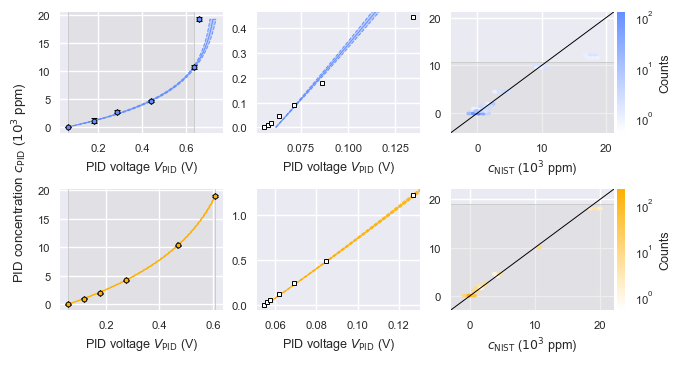

In [14]:
fig, axs = plt.subplots(
    number_gases,
    3,
    figsize=cm2inch((17, 9)),
    constrained_layout=True,
)

for ii, gas in enumerate(gases):
    ### voltage vs NIST concentration calibration ###
    axs[ii, 0].axvspan(
        *voltage_ranges[ii], edgecolor=None, facecolor=gray + "55", zorder=0
    )
    axs[ii, 0].axvline(voltage_ranges[ii][0], color=gray, zorder=1)
    axs[ii, 0].axvline(voltage_ranges[ii][1], color=gray, zorder=1)

    axs[ii, 0].errorbar(
        response_statistics[ii]["voltages_mean"],
        1e-3 * response_statistics[ii]["concentrations_mean"],
        xerr=response_statistics[ii]["voltages_sigma"],
        yerr=1e-3 * response_statistics[ii]["concentrations_sigma"],
        color=colors[ii],
        ecolor=black,
        markeredgecolor=black,
        fmt="o",
        capsize=2,
        zorder=10,
    )
    axs[ii, 0].plot(
        voltage_fits[ii],
        1e-3 * concentration_fits[ii],
        color=colors[ii],
        zorder=5,
    )
    axs[ii, 0].fill_betweenx(
        1e-3 * concentration_fits[ii],
        voltage_fits[ii] - voltage_fit_errors[ii],
        voltage_fits[ii] + voltage_fit_errors[ii],
        edgecolor=colors[ii],
        facecolor=colors[ii] + "55",
        linestyle="--",
        zorder=5,
    )

    axs[ii, 0].set_xlabel("PID voltage $V_\\mathrm{{PID}}$ (V)")
    axs[ii, 0].margins(0.05, 0.05)

    ### voltage vs PID concentration calibration ###
    axs[ii, 1].plot(
        voltage_fits[ii],
        1e-3 * concentration_fits[ii],
        color=colors[ii],
        zorder=5,
    )
    axs[ii, 1].fill_betweenx(
        1e-3 * concentration_fits[ii],
        voltage_fits[ii] - voltage_fit_errors[ii],
        voltage_fits[ii] + voltage_fit_errors[ii],
        edgecolor=colors[ii],
        facecolor=colors[ii] + "55",
        linestyle="--",
        zorder=5,
    )

    axs[ii, 1].plot(
        voltages_ethylene[ii],
        1e-3 * concentrations_ethylene[ii],
        color=black,
        markerfacecolor=white,
        markeredgecolor=black,
        marker="s",
        linestyle="none",
        zorder=15,
    )

    axs[ii, 1].set_xlabel("PID voltage $V_\\mathrm{{PID}}$ (V)")
    axs[ii, 1].set_xlim(
        np.min(voltages_ethylene[ii]) - 0.05 * np.ptp(voltages_ethylene[ii]),
        np.max(voltages_ethylene[ii]) + 0.05 * np.ptp(voltages_ethylene[ii]),
    )
    axs[ii, 1].set_ylim(
        np.min(1e-3 * concentrations_ethylene[ii])
        - 0.05 * np.ptp(1e-3 * concentrations_ethylene[ii]),
        np.max(1e-3 * concentrations_ethylene[ii])
        + 0.05 * np.ptp(1e-3 * concentrations_ethylene[ii]),
    )
    # axs[ii, 1].set_xlim(0.05, 0.2)
    # axs[ii, 1].set_ylim(1, 10_000)
    # axs[ii, 1].set_xscale("log")
    # axs[ii, 1].set_yscale("log")

    ### PID estimate vs NIST concentration ###
    colormap = LinearSegmentedColormap.from_list("white_to_color", [white, colors[ii]])

    concentration_minimum = min(
        concentration_estimates_nist_testing[:, ii].min(),
        concentration_estimates_pid_testing[:, ii].min(),
    )
    concentration_maximum = max(
        concentration_estimates_nist_testing[:, ii].max(),
        concentration_estimates_pid_testing[:, ii].max(),
    )
    concentration_limits = 1e-3 * np.array(
        [
            concentration_minimum
            - 0.1 * (concentration_maximum - concentration_minimum),
            concentration_maximum
            + 0.1 * (concentration_maximum - concentration_minimum),
        ]
    )

    concentration_value = cutoff_concentrations[ii]
    axs[ii, 2].axhspan(
        np.min(concentration_limits),
        1e-3 * cutoff_concentrations[ii],
        edgecolor=None,
        facecolor=gray + "55",
        zorder=5,
    )
    axs[ii, 2].axhline(1e-3 * cutoff_concentrations[ii], color=gray, zorder=6)

    hexbin = axs[ii, 2].hexbin(
        1e-3 * concentration_estimates_nist_testing[selection_mask_testing, ii],
        1e-3 * concentration_estimates_pid_testing[selection_mask_testing, ii],
        cmap=colormap,
        gridsize=(35, 25),
        mincnt=1,
        extent=(*concentration_limits, *concentration_limits),
        zorder=5,
    )
    hexbin.set_norm(LogNorm(vmin=0.5, vmax=hexbin.get_array().max()))

    axs[ii, 2].plot(
        concentration_limits,
        concentration_limits,
        color=black,
        zorder=10,
    )

    fig.colorbar(
        hexbin,
        ax=axs[ii, 2],
        location="right",
        label="Counts",
        aspect=15,
        pad=0.02,
    )

    axs[ii, 2].set_xlim(*concentration_limits)
    axs[ii, 2].set_ylim(*concentration_limits)
    axs[ii, 2].set_xlabel(f"$c_\\mathrm{{NIST}}$ ($10^3$ ppm)")

fig.supylabel("PID concentration $c_\\mathrm{PID}$ ($10^3$ ppm)")

filepath = Path("..", "Figures", f"s02-sensor-calibration-{configuration}.svg")
fig.savefig(filepath, dpi=600)